# 04 · DTI — Diffusion Tensor Imaging EDA
> *DTI measures water diffusion in white matter tracts, targeting the Substantia Nigra — the brain region most affected in PD.*

## Background: What is DTI?

Water molecules in the brain don't move randomly — in white matter tracts (bundles of nerve fibres), water diffuses **preferentially along** the fibre direction. **Diffusion Tensor Imaging (DTI)** measures this directed diffusion.

**Key DTI metrics:**

| Metric | Full Name | Meaning | In PD/damage |
|--------|-----------|---------|-------------|
| **FA** | Fractional Anisotropy | How *directional* diffusion is (0=random, 1=perfectly aligned) | **Decreases** when fibres are damaged or lost |
| **E1** | First Eigenvalue (axial diffusivity) | Diffusion *along* the fibre axis | Increases when axons degenerate |
| **E2** | Second Eigenvalue | Diffusion perpendicular to fibres | Increases when myelin is damaged |
| **E3** | Third Eigenvalue | Diffusion perpendicular to fibres | Increases when myelin is damaged |

**FA is the most commonly reported metric** — a high FA indicates intact, well-organised white matter.

---

## What is the Substantia Nigra?

The **Substantia Nigra** (SN) is a small but critical region in the midbrain. It contains the **dopamine-producing neurons** that degenerate in PD.

In this dataset, DTI measurements are taken in 6 ROIs (Regions of Interest) within the SN:

| Column | Location |
|--------|---------|
| `ROI1` | Left Rostral SN (front part) |
| `ROI2` | Left Middle SN |
| `ROI3` | Left Caudal SN (back part) |
| `ROI4` | Right Rostral SN |
| `ROI5` | Right Middle SN |
| `ROI6` | Right Caudal SN |
| `REF1` | Left reference white matter (healthy tract for comparison) |
| `REF2` | Right reference white matter |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.titlesize': 14,
                     'axes.labelsize': 12, 'xtick.labelsize': 10,
                     'ytick.labelsize': 10, 'figure.dpi': 120})
DATA_DIR = Path('../Imaging')
print(f'Data directory: {DATA_DIR.resolve()}')

Data directory: /Users/asadriaz/Desktop/PPMI Imaging/Imaging


In [2]:
VISIT_ORDER = ['SC', 'BL', 'V04', 'V06', 'V08', 'V10', 'V12', 'V14', 'V16', 'PW']
VISIT_LABELS = {'SC': 'Screening', 'BL': 'Baseline', 'PW': 'Withdrawal',
                'V04': 'Yr 1', 'V06': 'Yr 2', 'V08': 'Yr 3',
                'V10': 'Yr 4', 'V12': 'Yr 5', 'V14': 'Yr 6', 'V16': 'Yr 7'}
def ordered_visits(series):
    present = series.dropna().unique().tolist()
    ordered = [v for v in VISIT_ORDER if v in present]
    return ordered + sorted([v for v in present if v not in VISIT_ORDER])

## Load Data File

In [3]:
dti = pd.read_csv(DATA_DIR / 'DTI_Regions_of_Interest_12Nov2026.csv')
print(f'Shape: {dti.shape}')
print(f'Participants: {dti["PATNO"].nunique()}')
print(f'Measures: {dti["Measure"].unique()}')
print(f'Tissues: {dti["Tissue"].unique()}')
print(f'Rows per measure: {dti.groupby("Measure").size().to_dict()}')
dti.head(8)

Shape: (1200, 14)
Participants: 263
Measures: <StringArray>
['E1', 'E2', 'E3', 'FA']
Length: 4, dtype: str
Tissues: <StringArray>
['SN']
Length: 1, dtype: str
Rows per measure: {'E1': 300, 'E2': 300, 'E3': 300, 'FA': 300}


,PATNO,PAG_NAME,INFODT,Measure,Tissue,ROI1,ROI2,ROI3,ROI4,ROI5,ROI6,REF1,REF2,RUNDATE
0,3101,DTIROI,08/2012,E1,SN,0.000926,0.000877,0.000812,0.001246,0.001144,0.001088,0.001470,0.001434,2016-07-29
1,3101,DTIROI,08/2012,E2,SN,0.000604,0.000511,0.000587,0.001120,0.000945,0.000743,0.000537,0.000411,2016-07-29
2,3101,DTIROI,08/2012,E3,SN,0.000387,0.000337,0.000322,0.000900,0.000655,0.000463,0.000258,0.000243,2016-07-29
3,3102,DTIROI,11/2010,E1,SN,0.000926,0.000933,0.000967,0.000994,0.000971,0.001101,0.001348,0.001318,2016-07-29
4,3102,DTIROI,11/2010,E2,SN,0.000644,0.000591,0.000637,0.000531,0.000583,0.000721,0.000393,0.000269,2016-07-29
5,3102,DTIROI,11/2010,E3,SN,0.000376,0.000334,0.000356,0.000346,0.000284,0.000391,0.000153,0.000116,2016-07-29
6,3104,DTIROI,02/2011,E1,SN,0.000969,0.000942,0.001015,0.001051,0.001001,0.001043,0.001319,0.001410,2016-07-29
7,3104,DTIROI,02/2011,E2,SN,0.000667,0.000644,0.000665,0.000732,0.000752,0.000812,0.000355,0.000370,2016-07-29


## Column Reference

| Column | Meaning |
|--------|---------|
| `PATNO` | Participant ID |
| `PAG_NAME` | Form name (always "DTIROI") |
| `INFODT` | Date of data entry (MM/YYYY) |
| `Measure` | DTI metric: FA, E1, E2, or E3 |
| `Tissue` | Brain region (SN = Substantia Nigra) |
| `ROI1` | Left Rostral SN |
| `ROI2` | Left Middle SN |
| `ROI3` | Left Caudal SN |
| `ROI4` | Right Rostral SN |
| `ROI5` | Right Middle SN |
| `ROI6` | Right Caudal SN |
| `REF1` | Left reference white matter |
| `REF2` | Right reference white matter |
| `RUNDATE` | Date the analysis was run |

**Value ranges:**
- FA: 0–1 (typical SN values: 0.2–0.5)
- E1/E2/E3: very small numbers ~0.0005–0.002 (units: mm²/s)

## 1 · FA Distribution Across All 6 SN ROIs

FA tells us how intact the white matter is. Lower FA in the SN is associated with dopamine neuron loss.

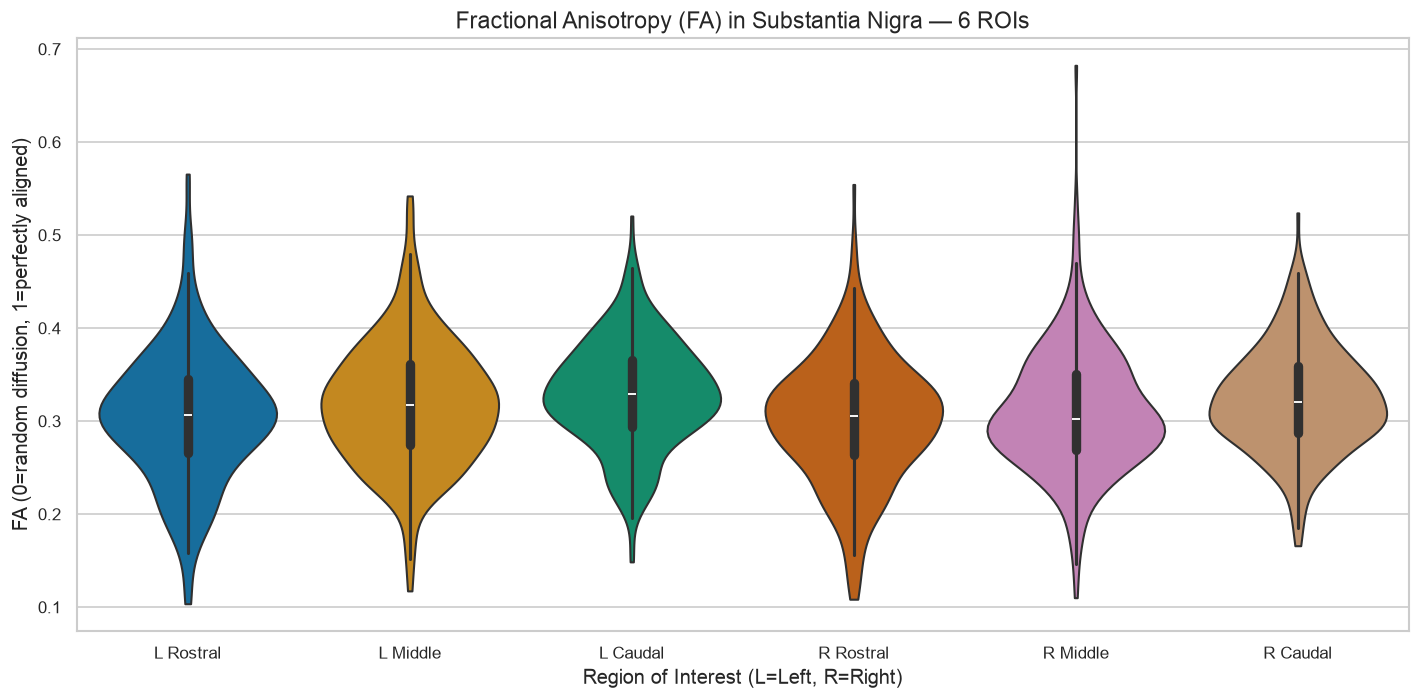

           count    mean     std     min     25%     50%     75%     max
ROI                                                                     
L Caudal   300.0  0.3289  0.0578  0.1487  0.2937  0.3287  0.3656  0.5206
L Middle   300.0  0.3182  0.0667  0.1175  0.2743  0.3178  0.3616  0.5422
L Rostral  300.0  0.3051  0.0709  0.1037  0.2657  0.3066  0.3450  0.5657
R Caudal   300.0  0.3238  0.0562  0.1661  0.2872  0.3203  0.3588  0.5239
R Middle   300.0  0.3105  0.0664  0.1102  0.2689  0.3027  0.3511  0.6826
R Rostral  300.0  0.3003  0.0676  0.1086  0.2640  0.3052  0.3411  0.5545


In [4]:
fa = dti[dti['Measure'] == 'FA'].copy()
roi_cols = [c for c in ['ROI1','ROI2','ROI3','ROI4','ROI5','ROI6'] if c in fa.columns]
roi_labels = {
    'ROI1': 'L Rostral', 'ROI2': 'L Middle', 'ROI3': 'L Caudal',
    'ROI4': 'R Rostral', 'ROI5': 'R Middle', 'ROI6': 'R Caudal'
}
fa_melt = fa[roi_cols].rename(columns=roi_labels).melt(var_name='ROI', value_name='FA').dropna()

fig, ax = plt.subplots(figsize=(12, 6))
sns.violinplot(data=fa_melt, x='ROI', y='FA', palette='colorblind', ax=ax, inner='box', cut=0)
ax.set_title('Fractional Anisotropy (FA) in Substantia Nigra — 6 ROIs')
ax.set_ylabel('FA (0=random diffusion, 1=perfectly aligned)')
ax.set_xlabel('Region of Interest (L=Left, R=Right)')
plt.tight_layout(); plt.show()
print(fa_melt.groupby('ROI')['FA'].describe().round(4))

## 2 · Left vs Right SN Comparison

Are the two sides of the SN symmetric? PD often starts asymmetrically.

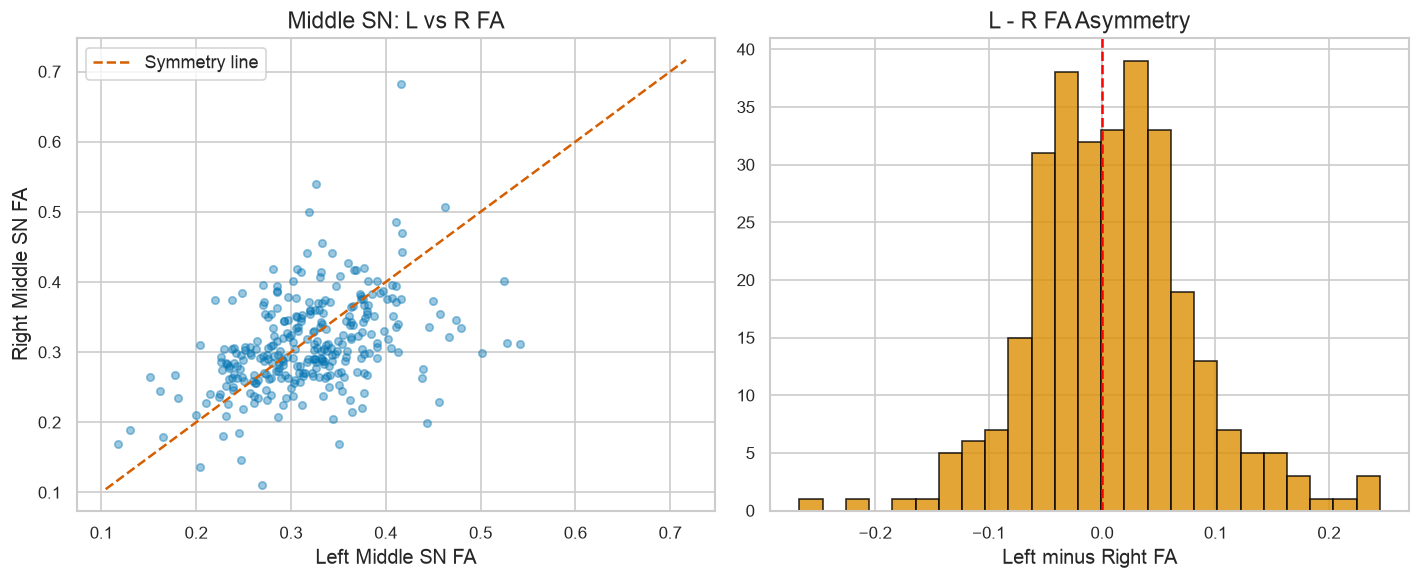

Mean L-R diff: 0.0078 | Std: 0.0717


In [5]:
fa = dti[dti['Measure'] == 'FA'].copy()
sides = [('ROI2','ROI5','Middle SN')]  # middle is most reliable
sides = [(l,r,n) for l,r,n in sides if l in fa.columns and r in fa.columns]

for lcol, rcol, name in sides:
    sub = fa[[lcol, rcol]].dropna()
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    mn = sub.min().min()*0.95; mx = sub.max().max()*1.05
    axes[0].scatter(sub[lcol], sub[rcol], alpha=0.4, s=20,
                    color=sns.color_palette('colorblind')[0])
    axes[0].plot([mn,mx],[mn,mx],'r--', label='Symmetry line')
    axes[0].set_xlabel(f'Left {name} FA'); axes[0].set_ylabel(f'Right {name} FA')
    axes[0].set_title(f'{name}: L vs R FA'); axes[0].legend()

    diff = sub[lcol] - sub[rcol]
    diff.hist(bins=25, ax=axes[1], color=sns.color_palette('colorblind')[1],
              edgecolor='black', alpha=0.8)
    axes[1].axvline(0, color='red', linestyle='--')
    axes[1].set_title('L - R FA Asymmetry')
    axes[1].set_xlabel('Left minus Right FA')
    plt.tight_layout(); plt.show()
    print(f'Mean L-R diff: {diff.mean():.4f} | Std: {diff.std():.4f}')

## 3 · Rostral vs Middle vs Caudal SN

The SN has distinct sub-regions. PD pathology may preferentially affect certain parts.

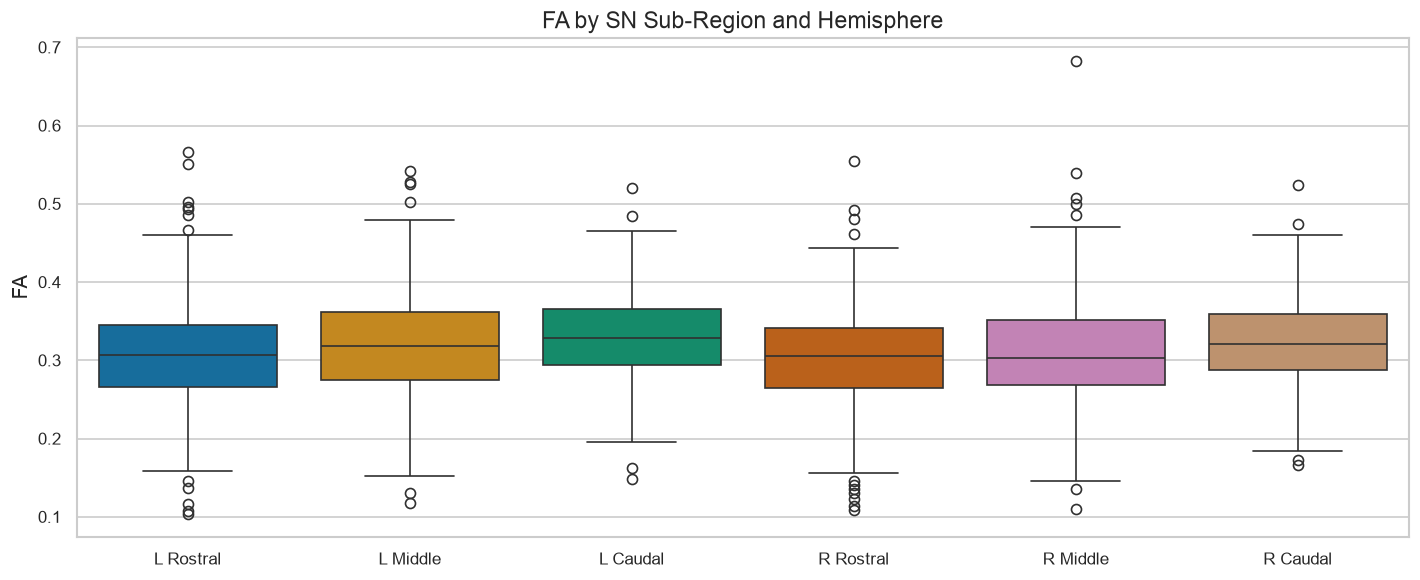

In [6]:
fa = dti[dti['Measure'] == 'FA'].copy()
groups = {
    'L Rostral': 'ROI1', 'L Middle': 'ROI2', 'L Caudal': 'ROI3',
    'R Rostral': 'ROI4', 'R Middle': 'ROI5', 'R Caudal': 'ROI6'
}
groups = {k: v for k, v in groups.items() if v in fa.columns}
plot_data = pd.concat([fa[v].rename(k) for k, v in groups.items()], axis=1)
melted = plot_data.melt(var_name='ROI', value_name='FA').dropna()

fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=melted, x='ROI', y='FA', palette='colorblind', ax=ax)
ax.set_title('FA by SN Sub-Region and Hemisphere')
ax.set_ylabel('FA'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

## 4 · All 4 DTI Measures Side by Side

Comparing FA, E1, E2, E3 across the middle SN (most common reference point).

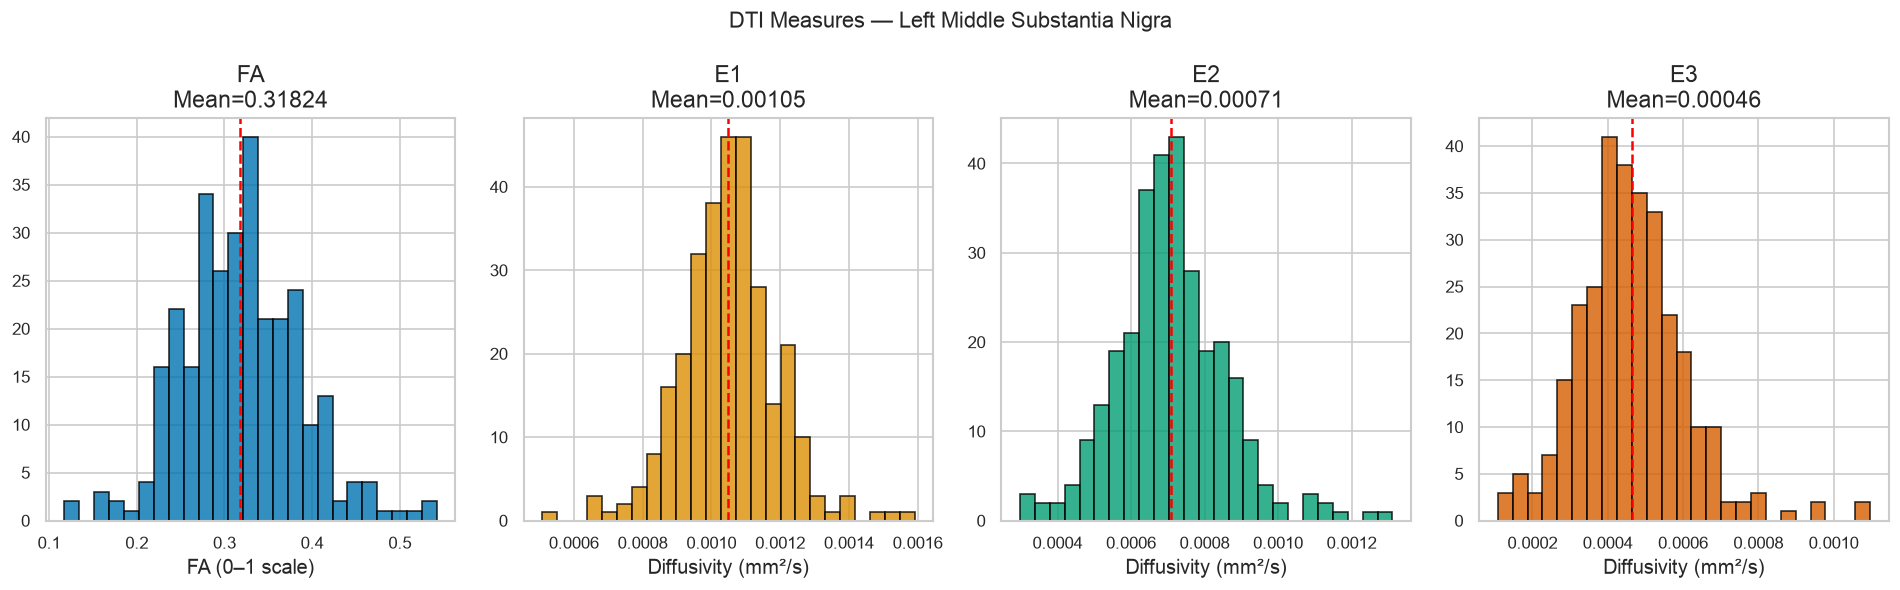

In [7]:
measures = ['FA', 'E1', 'E2', 'E3']
middle_col = 'ROI2'  # Left middle SN

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, measure in zip(axes, measures):
    sub = dti[dti['Measure'] == measure][middle_col].dropna()
    if len(sub) > 0:
        sub.hist(bins=25, ax=ax, color=sns.color_palette('colorblind')[measures.index(measure)],
                 edgecolor='black', alpha=0.8)
        ax.axvline(sub.mean(), color='red', linestyle='--', linewidth=1.5)
        ax.set_title(f'{measure}\nMean={sub.mean():.5f}')
        ax.set_xlabel('Value')
        if measure == 'FA':
            ax.set_xlabel('FA (0–1 scale)')
        else:
            ax.set_xlabel('Diffusivity (mm²/s)')
plt.suptitle('DTI Measures — Left Middle Substantia Nigra', fontsize=13)
plt.tight_layout(); plt.show()

## 5 · ROI vs Reference White Matter

We compare SN FA against the reference white matter tract. Healthy white matter (REF) should have higher FA than SN.

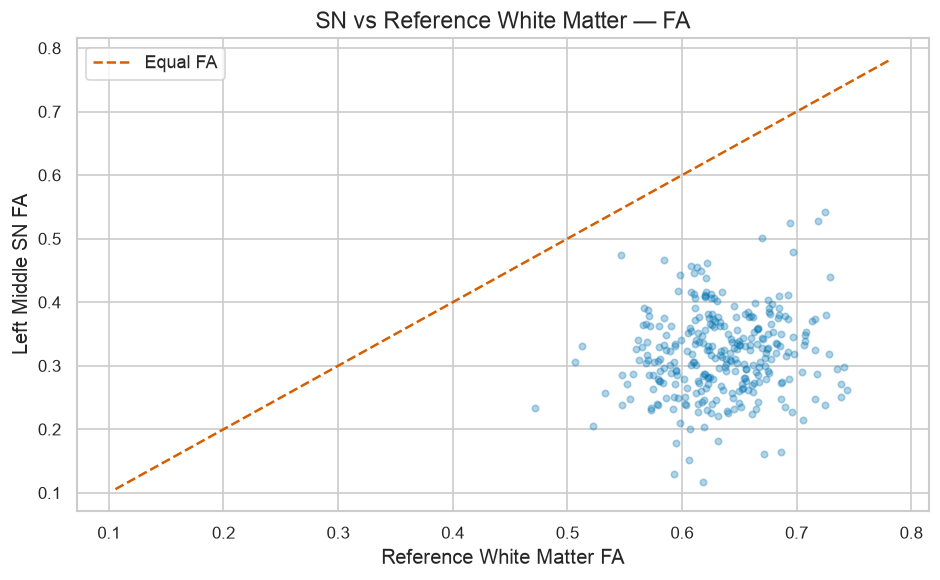

REF1 mean FA: 0.6340
ROI2 (L Mid SN) mean FA: 0.3182
SN is 50.2% of reference WM FA


In [8]:
fa = dti[dti['Measure'] == 'FA'].copy()
if 'ROI2' in fa.columns and 'REF1' in fa.columns:
    sub = fa[['ROI2','REF1']].dropna()
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(sub['REF1'], sub['ROI2'], alpha=0.3, s=15,
               color=sns.color_palette('colorblind')[0])
    mn = sub.min().min()*0.9; mx = sub.max().max()*1.05
    ax.plot([mn,mx],[mn,mx],'r--', label='Equal FA')
    ax.set_xlabel('Reference White Matter FA'); ax.set_ylabel('Left Middle SN FA')
    ax.set_title('SN vs Reference White Matter — FA')
    ax.legend(); plt.tight_layout(); plt.show()
    print(f'REF1 mean FA: {sub["REF1"].mean():.4f}')
    print(f'ROI2 (L Mid SN) mean FA: {sub["ROI2"].mean():.4f}')
    print(f'SN is {(sub["ROI2"].mean()/sub["REF1"].mean()*100):.1f}% of reference WM FA')

## Key Takeaways

- **FA in the Substantia Nigra is the key measure** — lower FA indicates white matter disruption associated with dopamine neuron loss
- **SN FA is lower than reference white matter** — expected, as the SN has complex architecture
- **L/R asymmetry in SN FA** may correlate with the side that develops symptoms first in PD
- **Small sample size (~300 participants)** compared to DaTSCAN — DTI was not acquired for everyone
- **E1 (axial diffusivity) increases** when axons degenerate; **E2/E3 (radial diffusivity) increases** when myelin is lost